In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from pydicom.data import get_testdata_file

ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))

for tag in ["PatientName", "PatientID", "Modality", "StudyInstanceUID",
            "SeriesInstanceUID", "SOPInstanceUID", "PixelSpacing",
            "SliceThickness", "RescaleSlope", "RescaleIntercept",
            "PhotometricInterpretation", "Rows", "Columns"]:
    print(f"{tag:28}", getattr(ds, tag, "(not present)"))

PatientName                  CompressedSamples^CT1
PatientID                    1CT1
Modality                     CT
StudyInstanceUID             1.3.6.1.4.1.5962.1.2.1.20040119072730.12322
SeriesInstanceUID            1.3.6.1.4.1.5962.1.3.1.1.20040119072730.12322
SOPInstanceUID               1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322
PixelSpacing                 [0.661468, 0.661468]
SliceThickness               5.000000
RescaleSlope                 1
RescaleIntercept             -1024
PhotometricInterpretation    MONOCHROME2
Rows                         128
Columns                      128


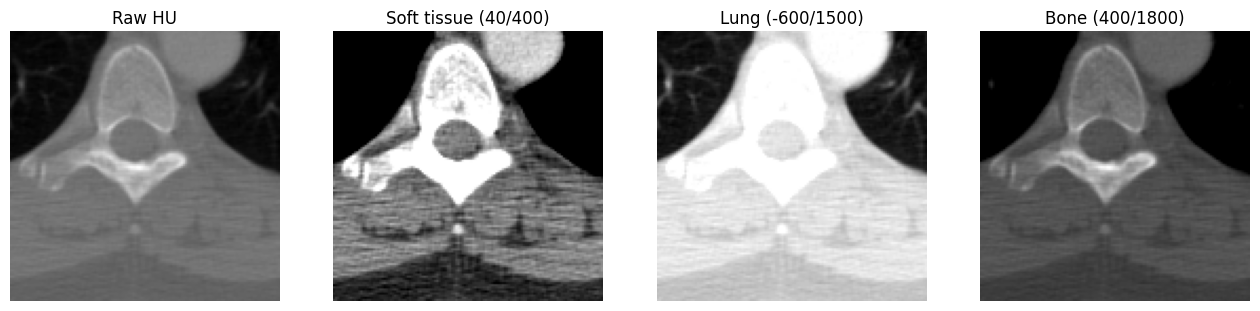

HU range: -896.0 to 1167.0


In [2]:
slope = float(getattr(ds, "RescaleSlope", 1))
intercept = float(getattr(ds, "RescaleIntercept", 0))
hu = ds.pixel_array.astype(np.float32) * slope + intercept   # raw values -> Hounsfield units

def window(img, center, width):
    return np.clip(img, center - width / 2, center + width / 2)

views = {"Raw HU": None,
         "Soft tissue (40/400)": (40, 400),
         "Lung (-600/1500)": (-600, 1500),
         "Bone (400/1800)": (400, 1800)}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, w) in zip(axes, views.items()):
    ax.imshow(hu if w is None else window(hu, *w), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.show()
print("HU range:", hu.min(), "to", hu.max())

This file is: MONOCHROME2


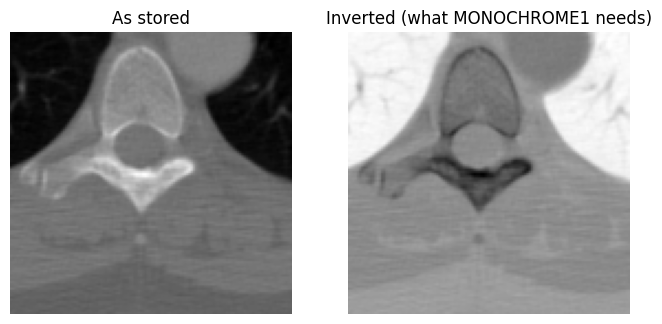

In [3]:
x = ds.pixel_array.astype(np.float32)
print("This file is:", ds.PhotometricInterpretation)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(x, cmap="gray");            ax[0].set_title("As stored")
ax[1].imshow(x.max() - x, cmap="gray");  ax[1].set_title("Inverted (what MONOCHROME1 needs)")
for a in ax: a.axis("off")
plt.show()

# 01 - DICOM Basics

**Goal**: understand how DICOM stores medical images before building the pipeline.
**For education only, not clinical use.**

## Key concepts

1. **Patient → Study → Series → Instance:** DICOM organizes data in four levels. A patient has studies (one visit or exam), a study has series (e.g. one scan sequence), and a series has instances (single images). Each level has a unique ID (StudyInstanceUID, SeriesInstanceUID, SOPInstanceUID).
2. **Tags:** every DICOM file stores metadata as tags, such as Modality, PatientID and PixelSpacing. Tags with patient identifiers (name, ID, birth date) must be anonymized before data is shared.
3. **Pixel data and Hounsfield units:** for CT, the stored pixel values are converted to Hounsfield units with `HU = pixel * RescaleSlope + RescaleIntercept`. HU is a standard scale where air is about -1000 and water is 0.
4. **Windowing:** WindowCenter and WindowWidth select which range of values is stretched across black to white. Different windows (lung, soft tissue, bone) show different structures in the same slice.
5. **MONOCHROME1 vs MONOCHROME2:** in MONOCHROME2, low values are dark. In MONOCHROME1, low values are white, so the image looks inverted unless it is flipped. Preprocessing must check this tag.
6. **PixelSpacing and slice thickness:** these give the real-world size of each pixel and the distance between slices, which matters for 3D models and for measuring anything in millimetres.

## What I observed

- The sample file is **MONOCHROME2**, so "As stored" is already correct. The inverted image is what you would get by wrongly flipping it.
- The HU range of the slice was **-896 to 1167**.
- The same slice looks very different under the raw, soft tissue, lung and bone windows, because each window shows a different HU range.

## Why this matters for the project

- Orthanc will give me DICOM files, so my inference service must apply the rescale and photometric checks before the model sees the image.
- NIH and MSD data are PNG and NIfTI, so I will convert them to DICOM to test the full pipeline.